# House Price Predictor 
## King County, Washington, USA (2015)

We will be training 3 models using different regression models (Support Vector Machine, Random Forest Regression, Linear Regression). The database is composed of a list of houses sales made in King County, Washington State, USA. Once complete, we will determine which model is the best to predict the price of a potential house for sale.

### 1. Importing the librairies

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import svm
from sklearn.svm import SVC
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.ensemble import RandomForestRegressor
import joblib

### 2. Loading the database

In [2]:
df_houses = pd.read_csv('/Users/cheikh/Documents/Projects/House Price Prediction/kc_house_data.csv')

### 3. Determining the object types of the variables in the database

In [3]:
object_cols = df_houses.select_dtypes(include=['object']).columns
print("Categorical variables:", len(object_cols))

int_cols = df_houses.select_dtypes(include=['int64']).columns
print("Integer variables:", len(int_cols))

fl_cols = df_houses.select_dtypes(include=['float64']).columns
print("Float variables:", len(fl_cols))

Categorical variables: 1
Integer variables: 15
Float variables: 5


### 4. Correlation Heatmap

This will allow us to have a better understanding of the relationships and dependency between each and every variable.

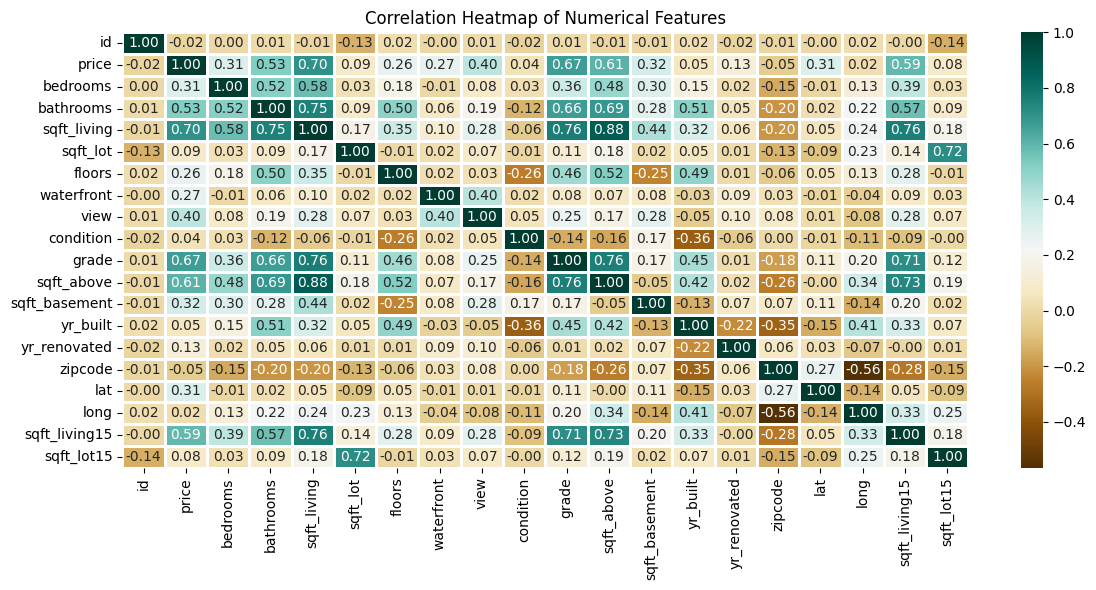

In [4]:
int_float_cols = df_houses.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(12, 6))
sns.heatmap(int_float_cols.corr(),
            cmap='BrBG',
            fmt='.2f',
            linewidths=2,
            annot=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

### 5. List of variables in the database

In [5]:
print(df_houses.columns.tolist())

['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


### 6. Dropping unnecessary columns

We will not be using the 'id' and 'date' columns to make our predictions, so they will be dropped before the creation of the training and validation sets.

In [6]:
df_houses = df_houses.drop(columns=['id', 'date'])

### 7. Filling possible empty cells in the 'price' column

If any cells in the 'price' column are missing, they will be filled with the mean of the values in the 'price' column.

In [7]:
df_houses['price'] = df_houses['price'].fillna(df_houses['price'].mean()) 
df_final = df_houses.dropna()
df_final.isnull().sum()

price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

### 8. Creation of the training and validation sets

We will be separating the dependant variable from the rest of the independent columns. In this case, the dependent variable is the price of the house. Afterwards, the dataset is split into seperate training and validation sets for each variable.

In [8]:
X = df_final.drop(['price'], axis=1)
Y = df_final['price']

X_train, X_valid, Y_train, Y_valid = train_test_split(
    X, Y, train_size=0.8, test_size=0.2, random_state=0)

### 9. Linear Regression Model

In [9]:
model_LR = LinearRegression()
model_LR.fit(X_train, Y_train)
Y_pred = model_LR.predict(X_valid)

print(mean_absolute_percentage_error(Y_valid, Y_pred))

0.25545278053009624


### 10. Support Vector Machine Regression Model

In [10]:
model_SVM = svm.SVR()
model_SVM.fit(X_train,Y_train)
Y_pred = model_SVM.predict(X_valid)

print(mean_absolute_percentage_error(Y_valid, Y_pred))

0.4260686712336606


### 11. Random Forest Regression Model

In [11]:
model_RFR = RandomForestRegressor(n_estimators=10)
model_RFR.fit(X_train, Y_train)
Y_pred = model_RFR.predict(X_valid)

print(mean_absolute_percentage_error(Y_valid, Y_pred))

0.132881957584124


### 12. Saving the selected model

After training all 3 models and generating a prediction, the Random Forest Regression Model showed to be the most accurate. The Mean Absolute Percentage Error (MAPE) is a metric used to determine the accuracy of a regression model. A MAPE between 10% and 20% is considered accurate, while anything over 20% is deemed to be unreliable ang highly volatile. The Random Forest Regression model had by far the best MAPE at 13.3%. The Linear Regression model had a MAPE of 25.5% and the Support Vector Machine had one of 42.6%. A possible reason for the gap in accuracy is that those 2 models cannot natively handle empty cells. The dataframe has a column 'Year Renovated (yr_renovated)' that can have empty entries meaning the house was never renovated.

In [ ]:
joblib.dump(model_RFR, "model_RFR.pkl")